# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Sankalp Tiwari
**Roll Number:** AP24110010356
**Date:** 09/10/2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [4]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 0.8812908992306927
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:* The 70/30 split will have the higher entropy.maximum entropy occurs at a 50/50 split where you are completely guessing (maximum uncertainty), and minimum entropy occurs at a 100/0 split where you know the outcome with absolute certainty


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [5]:
# Write your answer here
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p)))

parent = entropy([8, 6])
left = entropy([6, 0])
right = entropy([2, 6])

weighted_child = (6/14) * left + (8/14) * right
IG = parent - weighted_child

print("Parent Entropy:", parent)
print("Information Gain:", IG)

Parent Entropy: 0.9852281360342515
Information Gain: 0.5216406363433185


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [6]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [7]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [8]:
# Write your answer here
# 1.
for attribute in ['Outlook', 'Temperature', 'Humidity']:
    print(f"Gain({attribute}):", round(info_gain(tennis, attribute), 4))


# 2.
gains = {
    attribute: info_gain(tennis, attribute)
    for attribute in ['Outlook', 'Temperature', 'Humidity', 'Wind']
}
root = max(gains, key=gains.get)
print("Root attribute:", root)

# 3.
for value in ['Sunny', 'Rain']:
    subset = tennis[tennis['Outlook'] == value]
    print(f"\nBranch: {value}")
    for attribute in ['Temperature', 'Humidity', 'Wind']:
        print(f"Gain({attribute}):", round(info_gain(subset, attribute), 4))
    remaining = ['Temperature', 'Humidity', 'Wind']
    best_attribute = max(
        remaining,
        key=lambda attribute: info_gain(subset, attribute)
    )
    print("Next split:", best_attribute)

Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518
Root attribute: Outlook

Branch: Sunny
Gain(Temperature): 0.571
Gain(Humidity): 0.971
Gain(Wind): 0.02
Next split: Humidity

Branch: Rain
Gain(Temperature): 0.02
Gain(Humidity): 0.02
Gain(Wind): 0.971
Next split: Wind


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:* Because There will be no randomness or impurity in those feature so it is not needed to further split.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


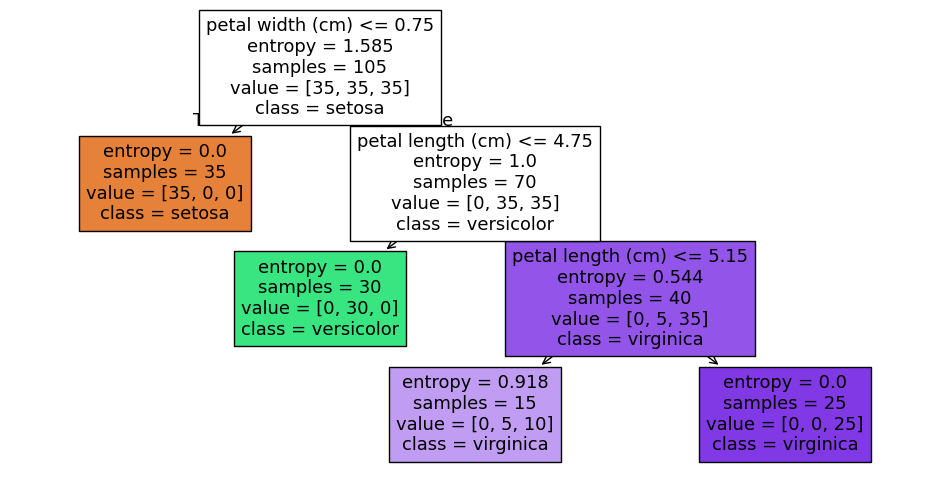

In [9]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


Depth:  1 | Train Accuracy: 0.6667 | Test Accuracy: 0.6667
Depth:  2 | Train Accuracy: 0.9524 | Test Accuracy: 0.9556
Depth:  3 | Train Accuracy: 0.9524 | Test Accuracy: 0.9556
Depth:  4 | Train Accuracy: 0.9524 | Test Accuracy: 0.9333
Depth:  5 | Train Accuracy: 0.9714 | Test Accuracy: 0.9778
Depth:  6 | Train Accuracy: 0.9810 | Test Accuracy: 0.9778
Depth:  7 | Train Accuracy: 0.9810 | Test Accuracy: 0.9778
Depth:  8 | Train Accuracy: 0.9905 | Test Accuracy: 0.9778
Depth:  9 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 10 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 11 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 12 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 13 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 14 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778
Depth: 15 | Train Accuracy: 1.0000 | Test Accuracy: 0.9778

Best depth: 5
Best test accuracy: 0.9778


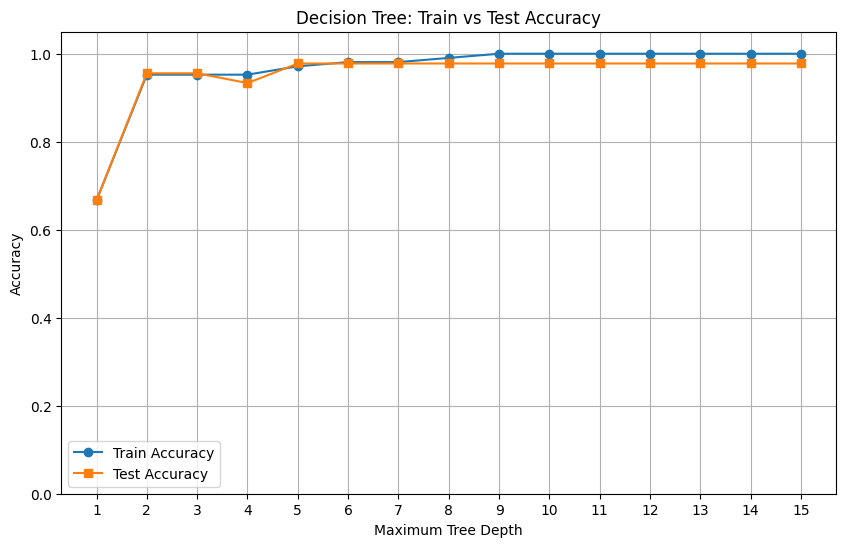

In [12]:
# Load dataset
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)

# Store results
depths = range(1, 16)
train_accuracies = []
test_accuracies = []

# Sweep max_depth from 1 to 15
for depth in depths:
    tree = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=1
    )

    tree.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, tree.predict(X_train))
    test_acc = accuracy_score(y_test, tree.predict(X_test))

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Depth: {depth:2d} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Test Accuracy: {test_acc:.4f}"
    )

# Find the depth with the highest test accuracy
best_index = test_accuracies.index(max(test_accuracies))
best_depth = list(depths)[best_index]
best_accuracy = test_accuracies[best_index]

print("\nBest depth:", best_depth)
print("Best test accuracy:", round(best_accuracy, 4))

# Plot train and test accuracy
plt.figure(figsize=(10, 6))

plt.plot(depths, train_accuracies, marker='o',
         label='Train Accuracy')
plt.plot(depths, test_accuracies, marker='s',
         label='Test Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Train vs Test Accuracy')
plt.xticks(list(depths))
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:* Week 6 - Polynomial Regression Formula
               Week 7 - Fitting a KNN according to distance


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [11]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


In [14]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)
print('Decision Tree test accuracy:', accuracy_score(yd_test, tree.predict(Xd_test)))


Decision Tree test accuracy: 0.8814814814814815


In [15]:
tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(Xd_train, yd_train)
print('Decision Tree test accuracy:', accuracy_score(yd_test, tree.predict(Xd_test)))

tree = DecisionTreeClassifier(criterion='entropy', max_depth=6, random_state=1)
tree.fit(Xd_train, yd_train)
print('Decision Tree test accuracy:', accuracy_score(yd_test, tree.predict(Xd_test)))

tree = DecisionTreeClassifier(criterion='entropy', max_depth=10, random_state=1)
tree.fit(Xd_train, yd_train)
print('Decision Tree test accuracy:', accuracy_score(yd_test, tree.predict(Xd_test)))

Decision Tree test accuracy: 0.5296296296296297
Decision Tree test accuracy: 0.8537037037037037
Decision Tree test accuracy: 0.8796296296296297


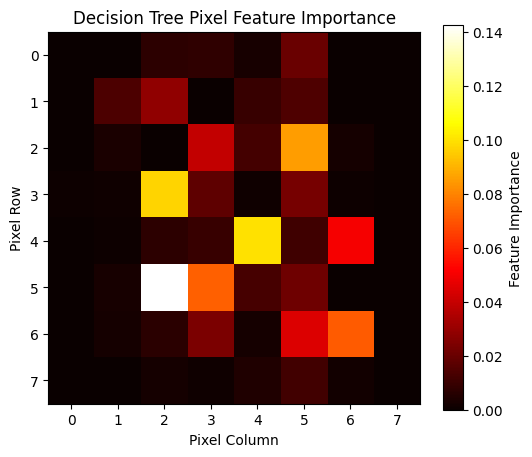

In [21]:

# Feature importance of the decision tree
tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=1
)
tree.fit(Xd_train, yd_train)

# Reshape 64 feature importances into an 8x8 image
importance = tree.feature_importances_.reshape(8, 8)

plt.figure(figsize=(6, 5))
plt.imshow(importance, cmap='hot', interpolation='nearest')
plt.colorbar(label='Feature Importance')
plt.title('Decision Tree Pixel Feature Importance')
plt.xlabel('Pixel Column')
plt.ylabel('Pixel Row')
plt.show()


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:* Less Accurate.KNN classifies digits using distances between similar handwritten images, while the Decision Tree makes decisions using selected pixel features


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [16]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [17]:
# Write your answer here
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(X_text, labels)
print(export_text(tree, feature_names=vocab))

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking



In [18]:
tree.predict(to_vector('the striker scored a goal', vocab).reshape(1, -1))

array(['sports'], dtype='<U7')

**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*
If we added three more sentences per topic, the decision tree might choose different split words because it learns patterns from the training data. With only a few sentences, the model may learn accidental patterns instead of general rules. This can lead to overfitting and incorrect predictions on unseen sentences. Therefore, a decision tree trained on very little data should not be trusted blindly. More diverse training examples and proper evaluation are needed to improve its reliability.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
